<a href="https://colab.research.google.com/github/rgonzalezp-ucsc/Ciencia-de-Datos_UCSC_Rodrigo_G/blob/main/S4_Notebook_CDD_GONZALEZ_RODRIGO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 4 — Minería de datos, validación y volumen
**Ciencia de Datos · Semana 4 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 2) · RA3 (transversal) |
| **Duración estimada** | 1,25 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `conjunto_explorado_RG.csv`, producido en la semana 3 |
| **Producto** | Este cuaderno completo — **es la Entrega 3** |
| **Estudiante** | _Rodrigo I. González Panes_ |

---

Esta semana pasas de **describir** a **descubrir**. Las tres técnicas de minería encuentran estructura que no se ve a simple vista; la validación decide si ese hallazgo se sostiene.

Las partes 1, 2 y 5 son **guiadas**, con los datos que trae el curso. Las partes 3 y 4 las aplicas sobre **tu propio conjunto**.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = '/content/'
SEMILLA = 20264
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

# En Google Colab, mlxtend ya viene instalado. En local:
# !pip install mlxtend scikit-learn
print('Listo')

Listo


---
## Parte 1 · Reglas de asociación

Una regla de asociación tiene la forma **A → B**: «quien lleva A, tiende a llevar B». Se miden con tres números, y confundirlos es el error clásico del tema.

| Métrica | Qué mide | Trampa |
|---|---|---|
| **Soporte** | Qué fracción de las canastas contiene A y B juntos | Una regla con soporte mínimo puede ser una casualidad |
| **Confianza** | De quienes llevan A, qué fracción lleva también B | **Sube sola si B es muy frecuente** |
| **Lift** | Cuántas veces más probable es B dado A, comparado con el azar | > 1 asociación real · = 1 independencia · < 1 se repelen |

In [ ]:
df = pd.read_csv(RUTA + 'S4_Dataset_Transacciones_CDD.csv', sep=';')
print('Líneas:', len(df), '· Transacciones:', df['transaccion_id'].nunique(),
      '· Productos:', df['producto'].nunique())
df.head()

### 1.1 De lista larga a matriz de canasta

Los algoritmos necesitan una matriz booleana: una fila por transacción, una columna por producto.

In [ ]:
cesta = (df.assign(v=1)
           .pivot_table(index='transaccion_id', columns='producto',
                        values='v', fill_value=0)
           .astype(bool))
print('Matriz:', cesta.shape)
cesta.iloc[:5, :6]

In [ ]:
# Frecuencia de cada producto: fíjate en los dos primeros
frecuencias = cesta.mean().sort_values(ascending=False)
frecuencias.head(8).round(3)

«pan» aparece en el 62 % de las canastas y «leche» en el 57 %. **Retén ese dato**: explica lo que viene a continuación.

### 1.2 Extraer las reglas

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuentes = apriori(cesta, min_support=0.05, use_colnames=True)
reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.10)

# nos quedamos con las reglas de un producto a un producto, más fáciles de leer
reglas = reglas[(reglas['antecedents'].str.len() == 1) &
                (reglas['consequents'].str.len() == 1)].copy()
reglas['regla'] = (reglas['antecedents'].map(lambda s: list(s)[0]) + ' → ' +
                   reglas['consequents'].map(lambda s: list(s)[0]))
print('Reglas encontradas:', len(reglas))

### 1.3 La trampa: ordenar por confianza

In [ ]:
reglas.nlargest(8, 'confidence')[['regla', 'support', 'confidence', 'lift']].round(3)

Aparecen mezcladas dos cosas muy distintas:

- `fideos → salsa de tomate` (confianza 0,78 · **lift 2,57**) — asociación real.
- `detergente → pan` (confianza 0,66 · **lift 1,06**) — ruido.

La segunda tiene confianza alta **solo porque el pan está en casi dos tercios de las canastas**. Quien lleva detergente lleva pan con la misma probabilidad que cualquiera.

### 1.4 El mismo cálculo, ordenado por lift

In [ ]:
reglas.nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

Ahora quedan solo las asociaciones reales: cerveza con papas fritas, vino con queso, fideos con salsa, café con azúcar. **El lift corrige por la frecuencia base del consecuente**, y por eso es la métrica que decide.

### 1.5 El contraejemplo definitivo

In [ ]:
for r in ['pan → leche', 'leche → pan']:
    f = reglas[reglas['regla'] == r]
    if len(f):
        print(f"{r:15s} soporte {f['support'].iloc[0]:.3f} · "
              f"confianza {f['confidence'].iloc[0]:.3f} · lift {f['lift'].iloc[0]:.3f}")

`leche → pan` tiene **confianza 0,61**: seis de cada diez compradores de leche llevan pan. Suena a regla fuerte.

Su **lift es 0,98**, por debajo de 1. Aparecen juntos **algo menos** de lo esperable por azar: son independientes. Si un sistema de recomendación se guiara por confianza, sugeriría pan a quien lleva leche, sin ganar nada.

> **Regla del oficio: filtra por soporte, ordena por lift, y usa la confianza solo para describir.**

### ✏️ Actividad 1.1

Extrae las reglas con **dos productos en el antecedente** (`antecedents.str.len() == 2`) y quédate con las tres de mayor lift. ¿Aportan algo que no dijeran ya las reglas simples?

In [ ]:
# Tu código aquí


_Tu lectura:_



---
## Parte 2 · Segmentación

La segmentación agrupa registros parecidos **sin que nadie haya definido los grupos**. Trabajaremos sobre el archivo de consumo eléctrico, construyendo un perfil por medidor.

In [ ]:
grande = pd.read_csv(RUTA + 'S4_Dataset_Grande_CDD.csv', sep=';')
grande['fecha_hora'] = pd.to_datetime(grande['fecha_hora'])
grande['hora'] = grande['fecha_hora'].dt.hour
print('Filas:', f'{len(grande):,}', '· Medidores:', grande['medidor_id'].nunique())
grande.head(3)

### 2.1 De 280.800 registros a 260 perfiles

No se segmentan las mediciones: se segmentan los **medidores**. El primer paso siempre es decidir cuál es la unidad y construir sus atributos.

In [ ]:
perfil = grande.groupby('medidor_id').agg(
    consumo_medio=('consumo_kwh', 'mean'),
    variabilidad=('consumo_kwh', 'std'),
    punta=('consumo_kwh', lambda s: s.quantile(0.95)),
)
nocturno = grande[grande['hora'].isin([0, 2, 4])].groupby('medidor_id')['consumo_kwh'].mean()
perfil['razon_nocturna'] = nocturno / perfil['consumo_medio']
perfil = perfil.dropna()
print('Perfiles:', perfil.shape)
perfil.describe().round(3)

### 2.2 Estandarizar es obligatorio

Los algoritmos de agrupamiento miden **distancias**. Si una variable va de 0 a 7 y otra de 0 a 1, la primera domina el resultado por su escala, no por su importancia.

In [ ]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(perfil)
print('Media de cada columna tras estandarizar:', X.mean(axis=0).round(3))
print('Desviación de cada columna            :', X.std(axis=0).round(3))

### 2.3 ¿Cuántos grupos?

No hay respuesta única. La **silueta** mide cuán separados quedan los grupos: va de −1 a 1, y valores sobre 0,5 indican una estructura clara.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X)
    s = silhouette_score(X, km.labels_)
    resultados.append((k, s, km.inertia_))
    print(f'k={k}  silueta={s:.3f}  inercia={km.inertia_:8.1f}  tamaños={np.bincount(km.labels_)}')

res = pd.DataFrame(resultados, columns=['k', 'silueta', 'inercia'])

In [ ]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(res['k'], res['inercia'], 'o-'); ax[0].set_title('Codo: inercia'); ax[0].set_xlabel('k')
ax[1].plot(res['k'], res['silueta'], 'o-', color='C1'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

La silueta es máxima en **k = 2** (≈ 0,51) y cae a ≈ 0,34 desde k = 3. Eso no significa que k = 2 sea «la verdad»: significa que la separación más nítida de estos datos es binaria.

> **El número de grupos es una decisión, no un resultado.** La silueta te dice cuán separados quedan; si necesitas tres segmentos porque hay tres políticas comerciales distintas, puedes usar k = 3 **declarando que la separación es más débil**.

### 2.4 Caracterizar los grupos

Un grupo sin nombre no sirve para decidir. Después de agrupar hay que describir en qué se diferencian.

In [ ]:
km = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit(X)
perfil['grupo'] = km.labels_

resumen = perfil.groupby('grupo').agg(['mean', 'count']).round(3)
display(perfil.groupby('grupo').mean().round(3))
print('\nTamaño de cada grupo:')
print(perfil['grupo'].value_counts().sort_index().to_string())

### ✏️ Actividad 2.1

Mira la tabla anterior y **ponle nombre a cada grupo** en una frase, a partir de sus valores medios. Un nombre útil describe el comportamiento, no el número: «alto consumo con punta vespertina» sirve; «grupo 2» no.

_Grupo 0:_ …

_Grupo 1:_ …

_Grupo 2:_ …

---
## Parte 3 · Detección de anomalías

Una anomalía es un registro que **no se parece a ninguno de los grupos**. La forma más directa de encontrarlas tras segmentar es medir la distancia de cada punto a su propio centro.

In [ ]:
distancias = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
perfil['distancia'] = distancias

umbral = np.percentile(distancias, 97)
anomalos = perfil[perfil['distancia'] > umbral]
print(f'Umbral (percentil 97): {umbral:.2f}')
print(f'Medidores anómalos: {len(anomalos)} de {len(perfil)}')
anomalos.sort_values('distancia', ascending=False).round(3).head(8)

In [ ]:
plt.hist(distancias, bins=40, edgecolor='white')
plt.axvline(umbral, color='C3', label=f'umbral p97 = {umbral:.2f}')
plt.legend(); plt.title('Distancia de cada medidor a su centro de grupo')
plt.xlabel('distancia'); plt.show()

> **El umbral lo eliges tú.** El percentil 97 no es una ley: es una decisión sobre cuántos casos quieres revisar. Súbelo si tienes poca capacidad de revisión, bájalo si el costo de no detectar es alto. Esa decisión va declarada.

### ✏️ Actividad 3.1 — La pregunta que ninguna fórmula responde

Toma los tres medidores más anómalos y **pronúnciate sobre cada uno**: ¿es un error de registro o un fenómeno real? Apóyate en sus valores concretos y en lo que sabes del dominio.

Recuerda la semana 2: lo imposible se corrige, lo raro se conserva.

In [ ]:
# Tu código aquí: mira el detalle de esos medidores en el archivo original


_Tu diagnóstico de los tres casos:_



### ✏️ Actividad 3.2 — Aplícalo a tu conjunto

Repite el recorrido completo sobre **tu propio conjunto de datos**:

1. Define la unidad que vas a segmentar y construye sus atributos numéricos.
2. Estandariza.
3. Prueba varios valores de k y elige uno, justificando con la silueta.
4. Caracteriza y **nombra** los grupos.
5. Detecta anomalías y pronúnciate sobre las tres más extremas.

In [3]:
# ============================================
# ACTIVIDAD 3.2:
# Arriendos diarios de bicicletas
# ============================================

mio = pd.read_csv(
    RUTA + 'conjunto_explorado_RG.csv',
    sep=';'
)

print('Dimensiones del conjunto:', mio.shape)

print('\nPrimeros cinco registros:')
display(mio.head())

print('\nTipos de variables:')
display(mio.dtypes)

print('\nResumen estadístico:')
display(mio.describe().round(2))

Dimensiones del conjunto: (731, 19)

Primeros cinco registros:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,anio,mes,dia_semana
0,1.0,2011-01-01,1.0,0.0,1.0,0.0,6.0,0.0,2.0,0.344167,0.363625,0.805833,0.160446,331.0,654.0,985.0,2011,1,5
1,2.0,2011-01-02,1.0,0.0,1.0,0.0,0.0,0.0,2.0,0.363478,0.353739,0.696087,0.248539,131.0,670.0,801.0,2011,1,6
2,3.0,2011-01-03,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.196364,0.189405,0.437273,0.248309,120.0,1229.0,1349.0,2011,1,0
3,4.0,2011-01-04,1.0,0.0,1.0,0.0,2.0,1.0,1.0,0.200000,0.212122,0.590435,0.160296,108.0,1454.0,1562.0,2011,1,1
4,5.0,2011-01-05,1.0,0.0,1.0,0.0,3.0,1.0,1.0,0.226957,0.229270,0.436957,0.186900,82.0,1518.0,1600.0,2011,1,2



Tipos de variables:


,0
instant,float64
dteday,object
season,float64
yr,float64
mnth,float64
holiday,float64
weekday,float64
workingday,float64
weathersit,float64
temp,float64



Resumen estadístico:


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,anio,mes,dia_semana
count,731.00,731.00,731.0,731.00,731.00,731.0,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.0,731.00,731.0
mean,366.00,2.50,0.5,6.52,0.03,3.0,0.68,1.40,0.50,0.47,0.63,0.19,848.18,3656.17,4504.35,2011.5,6.52,3.0
std,211.17,1.11,0.5,3.45,0.17,2.0,0.47,0.54,0.18,0.16,0.14,0.08,686.62,1560.26,1937.21,0.5,3.45,2.0
min,1.00,1.00,0.0,1.00,0.00,0.0,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00,2011.0,1.00,0.0
25%,183.50,2.00,0.0,4.00,0.00,1.0,0.00,1.00,0.34,0.34,0.52,0.13,315.50,2497.00,3152.00,2011.0,4.00,1.0
50%,366.00,3.00,1.0,7.00,0.00,3.0,1.00,1.00,0.50,0.49,0.63,0.18,713.00,3662.00,4548.00,2012.0,7.00,3.0
75%,548.50,3.00,1.0,10.00,0.00,5.0,1.00,2.00,0.66,0.61,0.73,0.23,1096.00,4776.50,5956.00,2012.0,10.00,5.0
max,731.00,4.00,1.0,12.00,1.00,6.0,1.00,3.00,0.86,0.84,0.97,0.51,3410.00,6946.00,8714.00,2012.0,12.00,6.0


In [4]:
# ============================================
# REVISION DE VARIABLES PARA SEGMENTACION
# ============================================

print('Dimensiones del conjunto:', mio.shape)

print('\nNombres de las variables:')
print(mio.columns.tolist())

print('\nCantidad de datos faltantes:')
print(mio.isnull().sum())

print('\nCantidad de registros duplicados:')
print(mio.duplicated().sum())

print('\nResumen de la variable principal CNT:')
print(mio['cnt'].describe().round(2))


Dimensiones del conjunto: (731, 19)

Nombres de las variables:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'anio', 'mes', 'dia_semana']

Cantidad de datos faltantes:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
anio          0
mes           0
dia_semana    0
dtype: int64

Cantidad de registros duplicados:
0

Resumen de la variable principal CNT:
count     731.00
mean     4504.35
std      1937.21
min        22.00
25%      3152.00
50%      4548.00
75%      5956.00
max      8714.00
Name: cnt, dtype: float64


### Revisión y diagnóstico inicial del conjunto de datos

En esta etapa se realizó una revisión general del conjunto de datos correspondiente a los arriendos diarios de bicicletas durante los años 2011 y 2012. El objetivo fue comprobar la calidad de la información antes de aplicar las técnicas de minería de datos.

El conjunto está compuesto por **731 registros y 19 variables**. Se revisaron los tipos de datos, la presencia de valores faltantes, los registros duplicados y las estadísticas descriptivas de la variable principal `cnt`, que representa la cantidad total de bicicletas arrendadas por día.

Los resultados muestran que no existen valores faltantes ni registros duplicados. Respecto de la demanda diaria, se obtuvo un promedio de **4.504,35 arriendos**, con una desviación estándar de **1.937,21**. Los valores observados van desde 22 hasta 8.714 arriendos diarios.

### Interpretación de los resultados

La revisión permite concluir que el conjunto presenta condiciones adecuadas para continuar con el análisis, ya que no se identificaron problemas de datos faltantes ni duplicidad de registros.

Sin embargo, la diferencia entre los valores mínimos y máximos, junto con la desviación estándar, evidencia una variabilidad importante en la demanda diaria. Esto sugiere que existen jornadas con comportamientos distintos en cuanto a la cantidad de bicicletas arrendadas.

A partir de estos antecedentes, se considera pertinente aplicar una técnica de segmentación que permita identificar grupos de días con características similares, considerando variables meteorológicas, temporales y de demanda. Esta clasificación permitirá explorar patrones que no son evidentes mediante una revisión descriptiva tradicional.

Variables seleccionadas:
['temp', 'hum', 'windspeed', 'cnt', 'season', 'weathersit', 'holiday', 'workingday']

Dimensiones de la matriz preparada: (731, 15)

COMPARACIÓN DE MODELOS K-MEANS:


,Cantidad de grupos,Coeficiente de silueta,Inercia
0,2,0.2297,3153.8956
1,3,0.2162,2664.8274
2,4,0.1840,2428.4786
3,5,0.1799,2232.0122



Cantidad de grupos seleccionada: 2


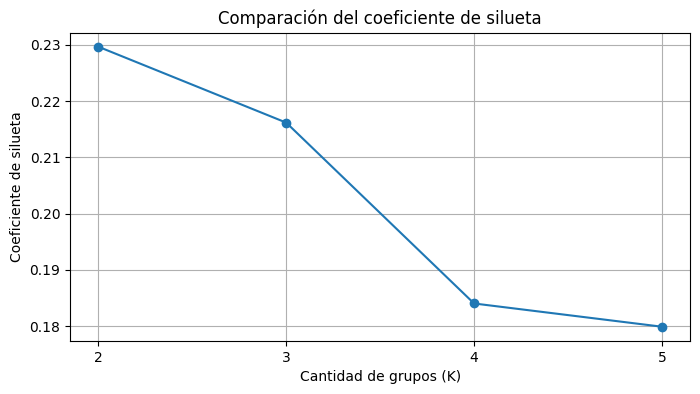


CANTIDAD DE DIAS POR GRUPO:


,Cantidad de días
grupo,
0,323
1,408



Segmentación completada correctamente.


In [5]:
# =====================================================
# ACTIVIDAD 3.2
# SEGMENTACION DE ARRIENDOS DIARIOS DE BICICLETAS
# METODO K-MEANS
# =====================================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Definir variables para la segmentación

variables_numericas = [
    'temp',
    'hum',
    'windspeed',
    'cnt'
]

variables_categoricas = [
    'season',
    'weathersit',
    'holiday',
    'workingday'
]

# 2. Construir conjunto de variables

columnas = variables_numericas + variables_categoricas

datos_segmentacion = mio[columnas].copy()

print('Variables seleccionadas:')
print(columnas)

# 3. Preparar y estandarizar los datos

preparador = ColumnTransformer(
    transformers=[
        ('numericas', StandardScaler(), variables_numericas),
        ('categoricas',
         OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         variables_categoricas)
    ]
)

X = preparador.fit_transform(datos_segmentacion)

print('\nDimensiones de la matriz preparada:', X.shape)

# 4. Comparar diferentes cantidades de grupos

resultados = []

for k in [2, 3, 4, 5]:

    modelo = KMeans(
        n_clusters=k,
        random_state=SEMILLA,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X)

    silueta = silhouette_score(X, etiquetas)

    resultados.append({
        'Cantidad de grupos': k,
        'Coeficiente de silueta': silueta,
        'Inercia': modelo.inertia_
    })

# 5. Mostrar resultados

tabla_k = pd.DataFrame(resultados)

print('\nCOMPARACIÓN DE MODELOS K-MEANS:')
display(tabla_k.round(4))

# 6. Seleccionar el modelo con mejor silueta

mejor_k = int(
    tabla_k.loc[
        tabla_k['Coeficiente de silueta'].idxmax(),
        'Cantidad de grupos'
    ]
)

print('\nCantidad de grupos seleccionada:', mejor_k)

# 7. Entrenar el modelo definitivo

km = KMeans(
    n_clusters=mejor_k,
    random_state=SEMILLA,
    n_init=20
)

etiquetas = km.fit_predict(X)

# 8. Incorporar los grupos al conjunto original

perfil = mio.copy()
perfil['grupo'] = etiquetas

# 9. Gráfico de comparación de silueta

plt.figure(figsize=(8, 4))

plt.plot(
    tabla_k['Cantidad de grupos'],
    tabla_k['Coeficiente de silueta'],
    marker='o'
)

plt.title('Comparación del coeficiente de silueta')
plt.xlabel('Cantidad de grupos (K)')
plt.ylabel('Coeficiente de silueta')
plt.xticks([2, 3, 4, 5])
plt.grid(True)
plt.show()

# 10. Resumen de registros por grupo

print('\nCANTIDAD DE DIAS POR GRUPO:')
display(
    perfil['grupo']
    .value_counts()
    .sort_index()
    .rename('Cantidad de días')
    .to_frame()
)

print('\nSegmentación completada correctamente.')

In [7]:
# ============================================
# CARACTERIZACION DE LOS GRUPOS
# ============================================

# Resumen de variables numéricas por grupo
resumen_grupos = perfil.groupby('grupo').agg(
    cantidad_dias=('cnt', 'count'),
    promedio_arriendos=('cnt', 'mean'),
    mediana_arriendos=('cnt', 'median'),
    temperatura_media=('temp', 'mean'),
    humedad_media=('hum', 'mean'),
    viento_medio=('windspeed', 'mean'),
    proporcion_dias_laborales=('workingday', 'mean'),
    proporcion_festivos=('holiday', 'mean')
).round(3)

print('CARACTERISTICAS DE CADA GRUPO:')
display(resumen_grupos)

# Variables categóricas más frecuentes
print('\nESTACION Y CLIMA PREDOMINANTES:')

for grupo in sorted(perfil['grupo'].unique()):

    datos_grupo = perfil[perfil['grupo'] == grupo]

    print(f'\nGrupo {grupo}')
    print('Estación predominante:',
          datos_grupo['season'].mode()[0])
    print('Situación meteorológica predominante:',
          datos_grupo['weathersit'].mode()[0])

CARACTERISTICAS DE CADA GRUPO:


,cantidad_dias,promedio_arriendos,mediana_arriendos,temperatura_media,humedad_media,viento_medio,proporcion_dias_laborales,proporcion_festivos
grupo,,,,,,,,
0,323,2986.015,2918.0,0.329,0.602,0.219,0.663,0.037
1,408,5706.363,5534.5,0.627,0.649,0.168,0.701,0.022



ESTACION Y CLIMA PREDOMINANTES:

Grupo 0
Estación predominante: 1.0
Situación meteorológica predominante: 1.0

Grupo 1
Estación predominante: 3.0
Situación meteorológica predominante: 1.0


### Interpretación de los grupos

La segmentación mediante K-Means permitió identificar dos grupos de jornadas. El primero reúne 323 días y presenta un promedio de 2.986 arriendos, mientras que el segundo reúne 408 días y registra un promedio de 5.706 arriendos.

También se observan diferencias en la temperatura media: el grupo 0 presenta un valor de 0,329 y el grupo 1 de 0,627, considerando la escala normalizada del conjunto de datos.

Estos resultados permiten caracterizar preliminarmente al grupo 0 como jornadas de menor demanda y al grupo 1 como jornadas de mayor demanda. Sin embargo, el coeficiente de silueta obtenido indica una separación limitada entre ambos grupos, por lo que los resultados deben interpretarse con cautela.

Umbral de anomalía (percentil 97): 3.1449
Cantidad de registros anómalos: 22

TRES DIAS MAS ANOMALOS:


,instant,dteday,cnt,temp,hum,windspeed,season,weathersit,grupo,distancia
49,50.0,2011-02-19,1635.0,0.3992,0.1879,0.5075,1.0,1.0,0,4.9518
68,69.0,2011-03-10,623.0,0.3891,0.0000,0.2619,1.0,3.0,0,4.6596
238,239.0,2011-08-27,1115.0,0.6800,0.8500,0.3756,3.0,2.0,0,3.8448


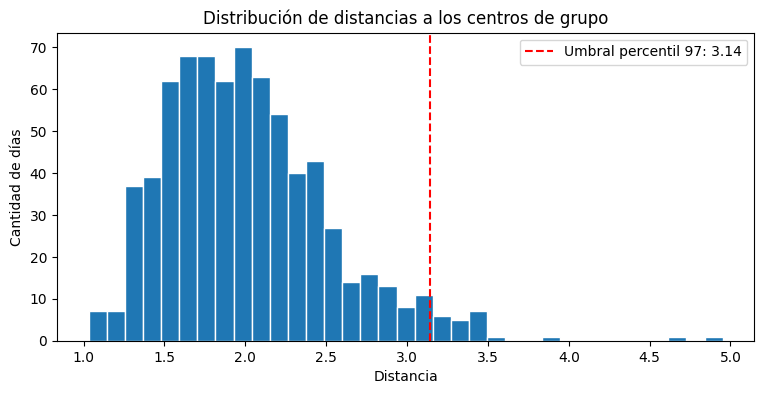

In [8]:
# ============================================
# DETECCION DE ANOMALIAS
# CONJUNTO DE ARRIENDOS DE BICICLETAS
# ============================================

# 1. Calcular distancia de cada día a su centro
distancias = np.linalg.norm(
    X - km.cluster_centers_[km.labels_],
    axis=1
)

# 2. Incorporar las distancias al conjunto
perfil['distancia'] = distancias

# 3. Definir umbral mediante percentil 97
umbral = np.percentile(distancias, 97)

# 4. Identificar registros anómalos
anomalias = perfil[perfil['distancia'] > umbral].copy()

print('Umbral de anomalía (percentil 97):', round(umbral, 4))
print('Cantidad de registros anómalos:', len(anomalias))

# 5. Seleccionar los tres casos más extremos
columnas_mostrar = [
    'instant',
    'dteday',
    'cnt',
    'temp',
    'hum',
    'windspeed',
    'season',
    'weathersit',
    'grupo',
    'distancia'
]

top_3 = (
    anomalias
    .sort_values('distancia', ascending=False)
    [columnas_mostrar]
    .head(3)
)

print('\nTRES DIAS MAS ANOMALOS:')
display(top_3.round(4))

# 6. Visualizar las distancias
plt.figure(figsize=(9, 4))

plt.hist(distancias, bins=35, edgecolor='white')
plt.axvline(
    umbral,
    color='red',
    linestyle='--',
    label=f'Umbral percentil 97: {umbral:.2f}'
)

plt.title('Distribución de distancias a los centros de grupo')
plt.xlabel('Distancia')
plt.ylabel('Cantidad de días')
plt.legend()
plt.show()

### Interpretación de las anomalías

Mediante el cálculo de distancias de cada registro respecto al centro de su grupo, se estableció un umbral correspondiente al percentil 97, con un valor de 3,1449. Como resultado, se identificaron 22 jornadas anómalas, equivalentes aproximadamente al 3,01 % del conjunto analizado.

Entre los tres casos más extremos se encuentran los días 19 de febrero, 10 de marzo y 27 de agosto de 2011, con 1.635, 623 y 1.115 arriendos, respectivamente.

Estos registros presentan comportamientos diferentes respecto a los patrones identificados mediante la segmentación. Sin embargo, su condición de anomalía no implica necesariamente un error en los datos, ya que también pueden representar situaciones reales de demanda influenciadas por factores meteorológicos o temporales.

_Tu lectura de los grupos y de las anomalías de tu conjunto: _El análisis de segmentación permitirá identificar jornadas con características similares según las condiciones meteorológicas, el calendario y la demanda de bicicletas. A partir de estos grupos, se buscarán comportamientos que se alejen de los patrones habituales. Las tres anomalías más extremas serán examinadas para determinar si representan situaciones reales de alta o baja demanda o posibles inconsistencias en los registros._



---
## Parte 4 · Validación: ¿el hallazgo se sostiene?

Encontrar un patrón es la parte fácil. La pregunta profesional es si ese patrón **seguiría estando** con otros datos, otra muestra u otra semilla.

### 4.1 Dos preguntas, dos destinos

Vamos a intentar predecir dos cosas distintas a partir del perfil de cada medidor, con el mismo método y los mismos datos:

- **La punta de consumo** (percentil 95), a partir del consumo medio, la variabilidad y la razón nocturna.
- **La razón nocturna**, a partir del consumo medio, la variabilidad y la punta.

Una de las dos se puede aprender. La otra no. Y el modelo no te lo va a decir: tienes que medirlo.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor

def comparar(y, columnas, titulo):
    Xv = perfil[columnas]
    X_tr, X_te, y_tr, y_te = train_test_split(Xv, y, test_size=0.3, random_state=SEMILLA)
    print(titulo)
    print(f"{'profundidad':>12s} {'R² train':>10s} {'R² test':>10s}")
    for prof in (2, 4, 8, 16, None):
        m = DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA).fit(X_tr, y_tr)
        print(f'{str(prof):>12s} {m.score(X_tr, y_tr):10.3f} {m.score(X_te, y_te):10.3f}')
    print()

comparar(perfil['punta'],
         ['consumo_medio', 'variabilidad', 'razon_nocturna'],
         'A · Predecir la PUNTA de consumo')
comparar(perfil['razon_nocturna'],
         ['consumo_medio', 'variabilidad', 'punta'],
         'B · Predecir la RAZÓN NOCTURNA')

### Lo que muestran las dos tablas

**Caso A — hay relación.** El R² de entrenamiento sube a 1,00 y el de prueba lo acompaña, quedándose en torno a 0,99. El modelo aprendió algo que también vale fuera de los datos con que aprendió.

**Caso B — no hay relación.** Mira la columna de la derecha: el R² de prueba es **negativo** y empeora a medida que el árbol se hace más profundo, hasta cerca de −0,9 con profundidad ilimitada. Mientras tanto, el de entrenamiento llega a **1,000**: perfecto.

> **Un R² negativo significa que el modelo predice peor que decir siempre el promedio.** Y aun así, sobre los datos de entrenamiento acierta todo. Eso es exactamente el sobreajuste: el árbol no encontró un patrón, **memorizó las filas**.

La lección práctica: si alguien te presenta un modelo con 98 % de acierto y no te dice sobre qué datos se midió, la cifra no significa nada. Un modelo siempre puede memorizar sus propios datos.

### 4.2 Validación cruzada

Una sola partición puede tocarte fácil o difícil por azar. La validación cruzada parte los datos en k pliegues, entrena k veces y promedia. Lo valioso no es solo la media: es la **desviación**, que dice cuán estable es el resultado.

In [ ]:
for etiqueta, y, cols in [
    ('A · punta         ', perfil['punta'],          ['consumo_medio', 'variabilidad', 'razon_nocturna']),
    ('B · razón nocturna', perfil['razon_nocturna'], ['consumo_medio', 'variabilidad', 'punta']),
]:
    for prof in (2, None):
        s = cross_val_score(DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA),
                            perfil[cols], y, cv=5, scoring='r2')
        print(f'{etiqueta}  prof={str(prof):>4s}  R² = {s.mean():7.3f} ± {s.std():.3f}   '
              f'pliegues {np.round(s, 2)}')

Dos lecturas:

- El caso A con profundidad ilimitada entrega **0,994 ± 0,003**: estable en los cinco pliegues.
- El caso B con profundidad ilimitada entrega algo como **−0,83 ± 0,25**. No solo es malo: es **inestable**. Según qué pliegue te toque, el resultado cambia mucho.

> **Reporta siempre media y desviación.** Un 0,80 ± 0,03 y un 0,80 ± 0,25 son resultados muy distintos, y el segundo no sostiene ninguna decisión.

### 4.3 Estabilidad de la segmentación

Un agrupamiento no tiene «respuesta correcta» contra la cual medirse, pero sí se puede comprobar si es **estable**: si con submuestras distintas aparece la misma estructura.

In [ ]:
siluetas = []
for i in range(20):
    idx = np.random.RandomState(SEMILLA + i).choice(len(X), int(len(X) * 0.8), replace=False)
    km_i = KMeans(n_clusters=3, random_state=SEMILLA + i, n_init=10).fit(X[idx])
    siluetas.append(silhouette_score(X[idx], km_i.labels_))

siluetas = np.array(siluetas)
print(f'Silueta sobre 20 submuestras del 80 %: {siluetas.mean():.3f} ± {siluetas.std():.3f}')
print(f'Rango: [{siluetas.min():.3f}, {siluetas.max():.3f}]')

### ✏️ Actividad 4.1 — Valida TU hallazgo

Toma el hallazgo principal de tu conjunto y estima su robustez con una de estas vías:

- Repite el análisis sobre 20 submuestras y reporta media ± desviación.
- Parte tus datos en dos mitades y comprueba si el patrón aparece en ambas.
- Si tienes una variable temporal, comprueba si el patrón se mantiene en períodos distintos.

Después responde: **¿este hallazgo sostiene una decisión, o solo sugiere una hipótesis?**

In [ ]:
# Tu código aquí


_Tu estimación de robustez y tu conclusión:_



---
## Parte 5 · Volumen y costo computacional

El archivo `S4_Dataset_Grande_CDD.csv` tiene 280.800 filas y unos 13 MB en disco. Todavía cabe en memoria, y justamente por eso sirve para **medir** qué pasa cuando deje de caber.

In [ ]:
import os, time

ruta = RUTA + 'S4_Dataset_Grande_CDD.csv'
print(f'Tamaño en disco: {os.path.getsize(ruta)/1024/1024:.1f} MB')

### Estrategia A · leer todo

In [ ]:
t0 = time.time()
completo = pd.read_csv(ruta, sep=';')
t_a = time.time() - t0
mem_a = completo.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_a:.2f} s · Memoria: {mem_a:.1f} MB · Filas: {len(completo):,}')

Fíjate: **13 MB en disco se convierten en unos 78 MB en memoria**. El texto de las columnas `medidor_id`, `comuna` y `tarifa` se guarda como objetos de Python, mucho más pesados que en el archivo.

### Estrategia B · leer solo las columnas necesarias

In [ ]:
t0 = time.time()
liviano = pd.read_csv(ruta, sep=';', usecols=['medidor_id', 'consumo_kwh'])
t_b = time.time() - t0
mem_b = liviano.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_b:.2f} s · Memoria: {mem_b:.1f} MB')
print(f'Reducción de memoria: {(1 - mem_b/mem_a)*100:.0f} %')

### Estrategia C · procesar por bloques

In [ ]:
t0 = time.time()
parciales = []
for bloque in pd.read_csv(ruta, sep=';', chunksize=50_000):
    parciales.append(bloque.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count']))
por_bloques = pd.concat(parciales).groupby(level=0).sum()
t_c = time.time() - t0
print(f'Tiempo: {t_c:.2f} s · Memoria máxima: la de UN bloque, no la del archivo')
print(f'Medidores agregados: {len(por_bloques)}')

In [ ]:
# Comprobación obligatoria: ¿da lo mismo que en memoria?
directo = completo.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count'])
iguales = np.allclose(por_bloques.sort_index()['sum'], directo.sort_index()['sum'])
print('¿Mismo resultado?', iguales)

### La conclusión, que no es la esperada

Compara los tiempos. Procesar por bloques **no es más rápido**: suele ser igual o algo más lento, porque el archivo se recorre igual y además hay que unir los resultados parciales.

> **El procesamiento por bloques no hace las cosas más rápidas: las hace posibles.** Lo que cambia no es el tiempo, es el techo de memoria. Con este archivo la diferencia es irrelevante; con uno de 40 GB, la estrategia A simplemente no corre.

Esa distinción —entre lo que acelera y lo que habilita— es la que hay que tener clara al elegir herramienta. Recurrir a procesamiento distribuido para un archivo que cabe en memoria añade complejidad sin ganar nada.

In [ ]:
print(f'A · todo el archivo : {t_a:5.2f} s · {mem_a:6.1f} MB')
print(f'B · dos columnas    : {t_b:5.2f} s · {mem_b:6.1f} MB')
print(f'C · por bloques     : {t_c:5.2f} s · memoria acotada al bloque')

### ✏️ Actividad 5.1

Responde en la celda siguiente: **¿a partir de qué tamaño de archivo cambiarías de estrategia, y por qué?** Toma como referencia la memoria disponible en tu entorno (en Google Colab, unos 12 GB).

Y una segunda: si tuvieras que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué harías y en qué orden?

_Tu respuesta:_



---
## Cierre y versionado

In [ ]:
mio.to_csv(RUTA + 'mi_conjunto_minado.csv', sep=';', index=False)
print('Guardado')

In [ ]:
# En una terminal:
# git add S4_Notebook_Laboratorio_CDD.ipynb mi_conjunto_minado.csv
# git commit -m 'Semana 4: mineria, validacion y volumen'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de entregar

- [ ] Al menos una técnica de minería aplicada a mi conjunto e interpretada
- [ ] Los grupos obtenidos tienen nombre descriptivo, no número
- [ ] Me pronuncié sobre las anomalías: error de registro o fenómeno real
- [ ] Un hallazgo validado, con su estimación de robustez (media ± desviación)
- [ ] Comparación del costo computacional de dos estrategias, con cifras propias
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

_Ciencia de Datos · Advance UCSC · Semana 4_